# Projet 3 — Classification d'espèces de fleurs
## Notebook 1 : Préparation et nettoyage des données

**Dataset imposé :** TF Flowers (TensorFlow Datasets) — **Classes retenues :** Daisy / Rose / Tulip

### Contraintes du protocole (section A du cahier des charges)

| # | Contrainte | Où dans ce notebook |
|---|-----------|---------------------|
| 1 | Sélectionner les 3 classes imposées | Étape 2 |
| 2 | Exactement **300 images par classe** (900 au total) | Étape 4 |
| 3 | Redimensionner en **32 × 32 × 3 (RGB)** | Étape 3 |
| 4 | Normaliser les pixels si nécessaire | Étape 7 |
| 5 | Séparation **stratifiée 60 / 20 / 20** avant tout choix d'hyperparamètres | Étape 6 |
| 6 | Visualiser des exemples + distribution des données | Étapes 5 et 8 |

**Sortie :** `data/flowers_cleaned.npz` (utilisé par le notebook 2 de modélisation).

## Étape 0 — Installation des bibliothèques

In [ ]:
# À décommenter sur Google Colab / environnement neuf
# !pip install -q tensorflow tensorflow-datasets scikit-learn matplotlib seaborn pandas

In [1]:
import os
import hashlib
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import tensorflow as tf
import tensorflow_datasets as tfds
from sklearn.model_selection import train_test_split

# ---- Paramètres du protocole ----
SEED = 42
TARGET_CLASSES = ["daisy", "roses", "tulips"]   # Daisy / Rose / Tulip (noms TFDS)
DISPLAY_NAMES = {"daisy": "Daisy", "roses": "Rose", "tulips": "Tulip"}
N_PER_CLASS = 300
IMG_SIZE = (32, 32)
OUT_DIR = "data"
OUT_FILE = os.path.join(OUT_DIR, "flowers_cleaned.npz")

np.random.seed(SEED)
tf.random.set_seed(SEED)
os.makedirs(OUT_DIR, exist_ok=True)
os.makedirs("figures", exist_ok=True)
sns.set_theme(style="whitegrid")
print("TensorFlow :", tf.__version__, "| TFDS :", tfds.__version__)

I0000 00:00:1793915287.899929   98524 port.cc:153] oneDNN custom operations are on. You may see slightly different numerical results due to floating-point round-off errors from different computation orders. To turn them off, set the environment variable `TF_ENABLE_ONEDNN_OPTS=0`.
I0000 00:00:1793915287.905145   98524 cudart_stub.cc:31] Could not find cuda drivers on your machine, GPU will not be used.
I0000 00:00:1793915288.285486   98524 cpu_feature_guard.cc:227] This TensorFlow binary is optimized to use available CPU instructions in performance-critical operations.
To enable the following instructions: AVX2 AVX512F AVX512_VNNI FMA, in other operations, rebuild TensorFlow with the appropriate compiler flags.
I0000 00:00:1793915290.722613   98524 port.cc:153] oneDNN custom operations are on. You may see slightly different numerical results due to floating-point round-off errors from different computation orders. To turn them off, set the environment variable `TF_ENABLE_ONEDNN_OPTS=0`.

TensorFlow : 2.22.0-rc0 | TFDS : 4.9.10


## Étape 1 — Téléchargement du dataset TF Flowers

TF Flowers contient 3 670 photos réparties en 5 classes (`dandelion`, `daisy`, `tulips`, `roses`, `sunflowers`),
avec un seul split `train`. Nous ne conservons que les trois classes imposées.

In [2]:
ds, info = tfds.load("tf_flowers", split="train", with_info=True, as_supervised=True)
ALL_NAMES = info.features["label"].names
print("Classes du dataset complet :", ALL_NAMES)
print("Nombre total d'images      :", info.splits["train"].num_examples)

# Vérification que nos 3 classes existent bien
assert all(c in ALL_NAMES for c in TARGET_CLASSES), "Classe introuvable dans TF Flowers"
TARGET_IDS = {ALL_NAMES.index(c): i for i, c in enumerate(TARGET_CLASSES)}   # id TFDS -> nouvel id 0/1/2
print("Correspondance id TFDS -> nouvel id :", TARGET_IDS)

Classes du dataset complet : ['dandelion', 'daisy', 'tulips', 'sunflowers', 'roses']
Nombre total d'images      : 3670
Correspondance id TFDS -> nouvel id : {1: 0, 4: 1, 2: 2}


E0000 00:00:1793915302.560121   98524 cuda_platform.cc:57] failed call to cuInit: INTERNAL: CUDA error: Failed call to cuInit: UNKNOWN ERROR (303)
=== Source Location Trace: === 
external/xla/xla/stream_executor/cuda/cuda_status.cc:50



## Étape 2 — Sélection des 3 classes imposées (Daisy / Rose / Tulip)
## Étape 3 — Redimensionnement en 32 × 32 × 3 (RGB)

On parcourt le dataset, on **ignore** les images des autres classes, puis on redimensionne chaque image retenue
en 32 × 32 (méthode `area`, adaptée à une forte réduction de taille, ce qui limite l'aliasing).
Les valeurs sont conservées en `uint8` (0–255) à ce stade.

In [3]:
def resize_32(img):
    # img : (H, W, 3) uint8  ->  (32, 32, 3) uint8
    out = tf.image.resize(img, IMG_SIZE, method="area")
    return tf.cast(tf.round(out), tf.uint8).numpy()

raw_images, raw_labels = [], []
for img, lab in tfds.as_numpy(ds):
    lab = int(lab)
    if lab in TARGET_IDS:                       # Étape 2 : garder uniquement les 3 classes
        if img.ndim == 3 and img.shape[-1] == 3:
            raw_images.append(resize_32(img))   # Étape 3 : 32 x 32 x 3
            raw_labels.append(TARGET_IDS[lab])

raw_images = np.stack(raw_images).astype(np.uint8)
raw_labels = np.array(raw_labels, dtype=np.int64)
print("Images retenues avant nettoyage :", raw_images.shape, raw_labels.shape)
print(pd.Series(raw_labels).map(dict(enumerate(TARGET_CLASSES))).value_counts())

I0000 00:00:1793915316.890213   98700 tf_record_dataset_op.cc:398] The default buffer size is 262144, which is overridden by the user specified `buffer_size` of 8388608


Images retenues avant nettoyage : (2073, 32, 32, 3) (2073,)
tulips    799
roses     641
daisy     633
Name: count, dtype: int64


### Nettoyage : valeurs invalides, images vides, doublons

Avant l'échantillonnage, on retire :
- les images contenant des valeurs non finies (NaN / inf) ou de mauvaise forme ;
- les images quasi constantes (écart-type < 1, donc sans information visuelle) ;
- les **doublons exacts** (une même image dans deux ensembles fausserait l'évaluation).

In [4]:
n0 = len(raw_images)

# 1) Forme et valeurs valides
valid = np.array([im.shape == (32, 32, 3) and np.isfinite(im).all() for im in raw_images])

# 2) Images (quasi) constantes
non_blank = raw_images.reshape(n0, -1).std(axis=1) >= 1.0

# 3) Doublons exacts (hash des pixels) : on garde la première occurrence
seen, unique = set(), np.zeros(n0, dtype=bool)
for i, im in enumerate(raw_images):
    h = hashlib.md5(im.tobytes()).hexdigest()
    if h not in seen:
        seen.add(h)
        unique[i] = True

keep = valid & non_blank & unique
print(f"Invalides        : {(~valid).sum()}")
print(f"Images vides     : {(~non_blank).sum()}")
print(f"Doublons exacts  : {(~unique).sum()}")
print(f"Conservées       : {keep.sum()} / {n0}")

clean_images, clean_labels = raw_images[keep], raw_labels[keep]
counts = np.bincount(clean_labels, minlength=3)
print("Disponibles par classe après nettoyage :", dict(zip(TARGET_CLASSES, counts)))
assert (counts >= N_PER_CLASS).all(), "Pas assez d'images dans une classe pour en garder 300"

Invalides        : 0
Images vides     : 0
Doublons exacts  : 1
Conservées       : 2072 / 2073
Disponibles par classe après nettoyage : {'daisy': np.int64(633), 'roses': np.int64(641), 'tulips': np.int64(798)}


## Étape 4 — Jeu équilibré : exactement 300 images par classe (900 au total)

Tirage aléatoire **reproductible** (graine fixe) de 300 images par classe, sans remise.

In [5]:
rng = np.random.default_rng(SEED)
sel_idx = []
for c in range(3):
    idx_c = np.where(clean_labels == c)[0]
    sel_idx.append(rng.choice(idx_c, size=N_PER_CLASS, replace=False))
sel_idx = np.concatenate(sel_idx)
rng.shuffle(sel_idx)

X = clean_images[sel_idx]            # uint8, (900, 32, 32, 3)
y = clean_labels[sel_idx]            # (900,)
CLASS_NAMES = [DISPLAY_NAMES[c] for c in TARGET_CLASSES]

assert X.shape == (900, 32, 32, 3) and y.shape == (900,)
assert (np.bincount(y) == N_PER_CLASS).all()
print("X :", X.shape, X.dtype, "| y :", y.shape)
print("Images par classe :", dict(zip(CLASS_NAMES, np.bincount(y))))

X : (900, 32, 32, 3) uint8 | y : (900,)
Images par classe : {'Daisy': np.int64(300), 'Rose': np.int64(300), 'Tulip': np.int64(300)}


## Étape 5 — Visualisation d'exemples de chaque classe

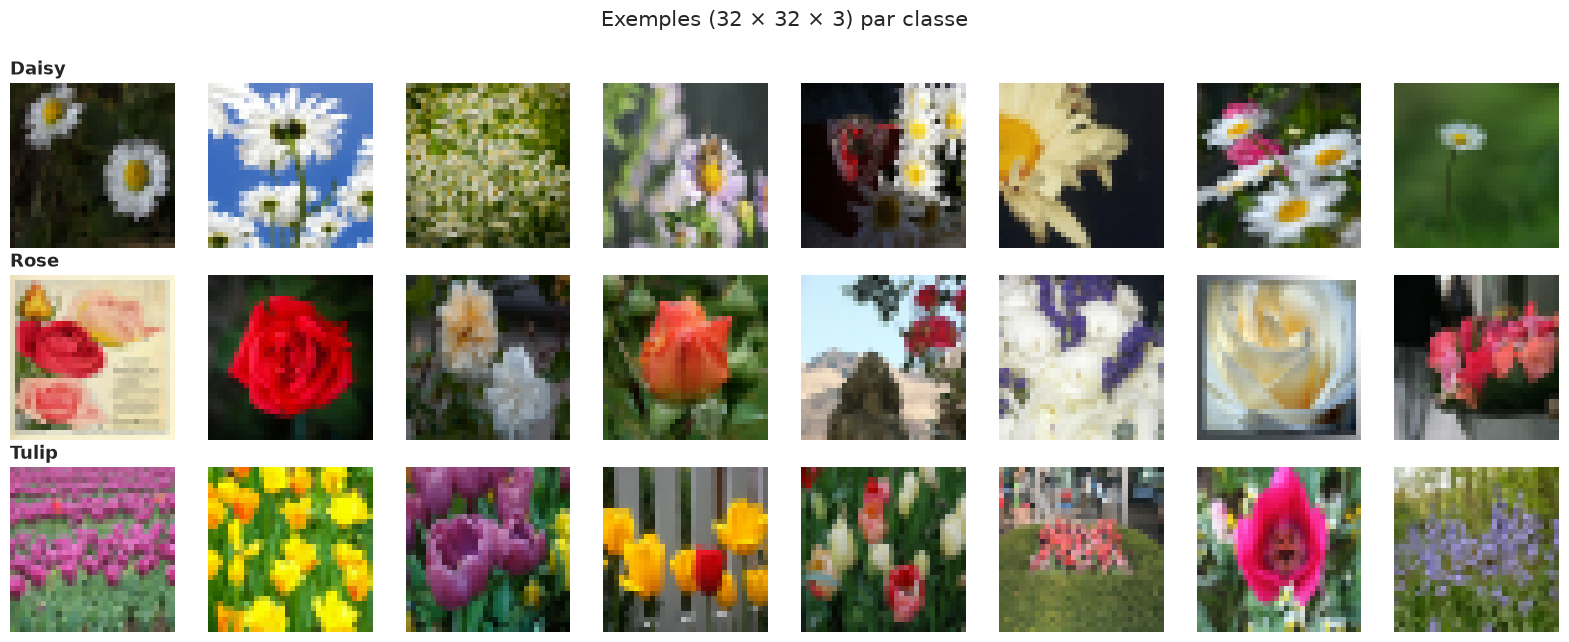

In [6]:
n_show = 8
fig, axes = plt.subplots(3, n_show, figsize=(2 * n_show, 6.4))
for c in range(3):
    idx = np.where(y == c)[0][:n_show]
    for j, i in enumerate(idx):
        axes[c, j].imshow(X[i])
        axes[c, j].axis("off")
        if j == 0:
            axes[c, j].set_title(CLASS_NAMES[c], fontsize=13, loc="left", fontweight="bold")
plt.suptitle("Exemples (32 × 32 × 3) par classe", fontsize=15, y=1.0)
plt.tight_layout()
plt.savefig("figures/01_exemples_classes.png", dpi=150, bbox_inches="tight")
plt.show()

## Étape 6 — Séparation stratifiée 60 % / 20 % / 20 %

Séparation faite **une seule fois, avant toute sélection d'hyperparamètres** :
1. on isole d'abord 20 % pour le **test** ;
2. on prend 25 % du reste (= 20 % du total) pour la **validation** ;
3. le reste (60 % du total) sert à l'**entraînement**.

Le paramètre `stratify` garantit la même proportion de chaque classe dans les trois ensembles (180 / 60 / 60 par classe).

In [8]:
X_tmp, X_test, y_tmp, y_test = train_test_split(
    X, y, test_size=0.20, stratify=y, random_state=SEED)
X_train, X_val, y_train, y_val = train_test_split(
    X_tmp, y_tmp, test_size=0.25, stratify=y_tmp, random_state=SEED)   # 0.25 * 0.8 = 0.20

print(f"Train : {X_train.shape[0]} images ({X_train.shape[0]/900:.0%})")
print(f"Val   : {X_val.shape[0]} images ({X_val.shape[0]/900:.0%})")
print(f"Test  : {X_test.shape[0]} images ({X_test.shape[0]/900:.0%})")

assert (len(X_train), len(X_val), len(X_test)) == (540, 180, 180)
for name, yy in [("train", y_train), ("val", y_val), ("test", y_test)]:
    assert (np.bincount(yy) == np.bincount(yy)[0]).all(), f"{name} non stratifié"

# Aucune image partagée entre deux ensembles
h = lambda A: {hashlib.md5(a.tobytes()).hexdigest() for a in A}
assert not (h(X_train) & h(X_val)) and not (h(X_train) & h(X_test)) and not (h(X_val) & h(X_test))
print("OK : stratification respectée et aucun recouvrement entre les ensembles.")

Train : 540 images (60%)
Val   : 180 images (20%)
Test  : 180 images (20%)
OK : stratification respectée et aucun recouvrement entre les ensembles.


## Étape 7 — Normalisation des pixels

Les pixels `uint8` ∈ [0, 255] sont ramenés dans **[0, 1]** (division par 255) et convertis en `float32`.
Cette mise à l'échelle est fixe : elle n'utilise **aucune statistique** calculée sur les données, donc aucune fuite
d'information du jeu de test vers l'entraînement. Elle est utile pour l'entraînement des réseaux (Softmax, CNN)
et met les distances du k-NN à une échelle cohérente.

In [9]:
def normalize(a):
    return (a.astype("float32") / 255.0)

X_train_n, X_val_n, X_test_n = normalize(X_train), normalize(X_val), normalize(X_test)

for n, a in [("train", X_train_n), ("val", X_val_n), ("test", X_test_n)]:
    print(f"{n:5s} : shape={a.shape}, dtype={a.dtype}, min={a.min():.2f}, max={a.max():.2f}, "
          f"NaN={np.isnan(a).sum()}")

train : shape=(540, 32, 32, 3), dtype=float32, min=0.00, max=1.00, NaN=0
val   : shape=(180, 32, 32, 3), dtype=float32, min=0.00, max=1.00, NaN=0
test  : shape=(180, 32, 32, 3), dtype=float32, min=0.00, max=1.00, NaN=0


## Étape 8 — Distribution des données (par ensemble et par classe)

,Train,Validation,Test
Daisy,180,60,60
Rose,180,60,60
Tulip,180,60,60
Total,540,180,180


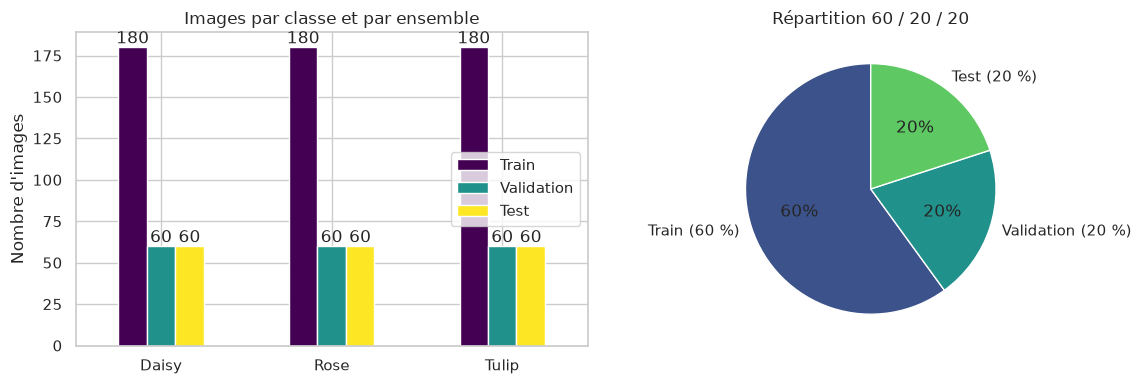

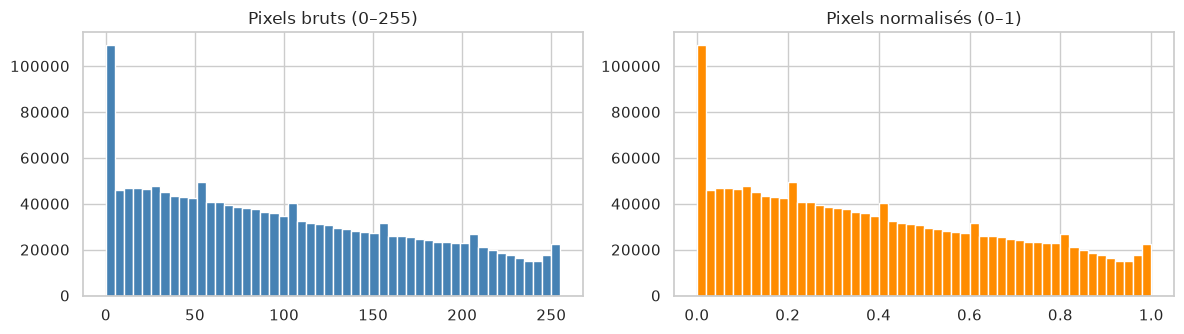

In [10]:
dist = pd.DataFrame({
    "Train": np.bincount(y_train),
    "Validation": np.bincount(y_val),
    "Test": np.bincount(y_test),
}, index=CLASS_NAMES)
dist.loc["Total"] = dist.sum()
display(dist)

fig, axes = plt.subplots(1, 2, figsize=(12, 4))
dist.drop("Total").plot(kind="bar", ax=axes[0], rot=0, colormap="viridis")
axes[0].set_title("Images par classe et par ensemble")
axes[0].set_ylabel("Nombre d'images")
for cont in axes[0].containers:
    axes[0].bar_label(cont)

axes[1].pie(dist.loc["Total"][["Train", "Validation", "Test"]],
            labels=["Train (60 %)", "Validation (20 %)", "Test (20 %)"],
            autopct="%1.0f%%", colors=sns.color_palette("viridis", 3), startangle=90)
axes[1].set_title("Répartition 60 / 20 / 20")
plt.tight_layout()
plt.savefig("figures/02_distribution_donnees.png", dpi=150, bbox_inches="tight")
plt.show()

# Distribution des intensités de pixels (avant / après normalisation)
fig, axes = plt.subplots(1, 2, figsize=(12, 3.5))
axes[0].hist(X_train.ravel(), bins=50, color="steelblue"); axes[0].set_title("Pixels bruts (0–255)")
axes[1].hist(X_train_n.ravel(), bins=50, color="darkorange"); axes[1].set_title("Pixels normalisés (0–1)")
plt.tight_layout()
plt.savefig("figures/03_histogramme_pixels.png", dpi=150, bbox_inches="tight")
plt.show()

## Étape 9 — Sauvegarde des données nettoyées au format `.npz`

Le fichier contient les 3 ensembles normalisés (`float32`, [0, 1]) et les étiquettes (`int64`, 0 = Daisy, 1 = Rose, 2 = Tulip).

In [11]:
np.savez_compressed(
    OUT_FILE,
    X_train=X_train_n, y_train=y_train,
    X_val=X_val_n,     y_val=y_val,
    X_test=X_test_n,   y_test=y_test,
    class_names=np.array(CLASS_NAMES),
)
print(f"Sauvegardé : {OUT_FILE} ({os.path.getsize(OUT_FILE)/1e6:.1f} Mo)")

# Vérification par rechargement
chk = np.load(OUT_FILE)
for k in chk.files:
    print(f"{k:12s}", chk[k].shape, chk[k].dtype)
assert np.array_equal(chk["X_test"], X_test_n) and list(chk["class_names"]) == CLASS_NAMES
print("Rechargement OK.")

# Sur Google Colab, décommenter pour télécharger le fichier :
# from google.colab import files; files.download(OUT_FILE)

Sauvegardé : data/flowers_cleaned.npz (3.9 Mo)
X_train      (540, 32, 32, 3) float32
y_train      (540,) int64
X_val        (180, 32, 32, 3) float32
y_val        (180,) int64
X_test       (180, 32, 32, 3) float32
y_test       (180,) int64
class_names  (3,) <U5
Rechargement OK.


## Récapitulatif de la préparation

| Contrainte | Résultat |
|---|---|
| 3 classes | Daisy / Rose / Tulip |
| 300 images par classe | 900 images, jeu équilibré |
| Taille | 32 × 32 × 3 (RGB) |
| Nettoyage | invalides, images vides, doublons exacts retirés |
| Split stratifié | 540 train / 180 val / 180 test (180 / 60 / 60 par classe) |
| Normalisation | division par 255 → [0, 1], `float32` |
| Sauvegarde | `data/flowers_cleaned.npz` |

➡️ Passer au **notebook 2** (`02_modelisation_evaluation.ipynb`).